# **Linear Cryptanalysis**

## **MiniSPN**

### **Kiến trúc**

![miniSPN](miniSPN.svg)

In [44]:
from toys.minispn import miniSPN

print(f'{miniSPN.block_size = }')
print(f'{miniSPN.num_rounds = }')
print(f'{miniSPN.sbox_size  = }')
print(f'{miniSPN.sbox = }')
print(f'{miniSPN.perm = }')

miniSPN.block_size = 48
miniSPN.num_rounds = 6
miniSPN.sbox_size  = 6
miniSPN.sbox = [42, 35, 11, 41, 30, 47, 26, 61, 18, 51, 49, 58, 1, 34, 7, 5, 6, 23, 9, 37, 12, 19, 14, 27, 16, 36, 62, 54, 46, 45, 57, 21, 53, 32, 33, 39, 59, 52, 43, 15, 4, 63, 38, 8, 13, 0, 55, 2, 40, 50, 25, 48, 44, 28, 3, 17, 56, 29, 20, 10, 60, 31, 22, 24]
miniSPN.perm = [0, 6, 12, 18, 24, 30, 36, 42, 1, 7, 13, 19, 25, 31, 37, 43, 2, 8, 14, 20, 26, 32, 38, 44, 3, 9, 15, 21, 27, 33, 39, 45, 4, 10, 16, 22, 28, 34, 40, 46, 5, 11, 17, 23, 29, 35, 41, 47]


### **Phân tích LAT**

- Đầu tiên ta xây dựng 1 bảng linear approximation table

In [45]:
def make_lat(sbox):
    n = len(sbox)
    lat = [[0]*n for _ in range(n)]

    for x in range(n):
        for y in range(n):
            lat[x][y] = 32 - sum([((x&i)^(y&sbox[i])).bit_count() % 2 for i in range(n)]) 

    return lat

lat = make_lat(miniSPN.sbox)

for row in lat:
    print(' '.join(f'{x:>3}' for x in row))

 32   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
  0   4   0  -4   0 -12   4   0  -4  -4   0   0  -4   4   4  -4   2  -2  -2   2  -2  -6  -2   2  -2  -2  -2  -2   2  -6   6  -2   2   2  -2  -2  -2  -2  -2  -2   6  10  -2  10   2  -2  -2   2   4 -12   4   4  -4  -4   0   0   0  -4  -4   0   0   4   0  -4
  0   6   2   8  -4   2  -6   0   0   2  -2   0  12  -2  -2   0   0   6   6  -4   0  -2   2   0   0   2   2   4   0  -6   6   0  -4  -2   2  -4  -4  -2   6   0   4   2  -2   4   4   2  10   0  -4  -2   6   0   0  -6  -2   0   4   2   2  -8  -8  -2   2   0
  0   6   6  -4   0   6  -2   4  -4  -6   2  -8  -4   2   2   0   2   0   0  -2  -6   0   0 -10  -2  -4  -4   2  -2  -4  -4   2   2   0   0  -2   2   0   0  -2   6   4   4  -6   6  -4  -4  -6   4   2   2   0  -4   2  -6   0   0   6 

- Từ bảng lat ta chọn các phương trình sao cho nó có bias cao nhất

In [46]:
from itertools import product

n = len(miniSPN.sbox)
flatten = [(x, y, lat[x][y]) for x, y in product(range(n), range(n))]
flatten.sort(key = lambda e: abs(e[-1]))

for x, y, c in flatten[-29:-1]:
    print(f'{x:06b} | {y:06b} | {c:3} | {c/n}')

000001 | 000101 | -12 | -0.1875
000001 | 110001 | -12 | -0.1875
000010 | 001100 |  12 | 0.1875
000100 | 011100 | -12 | -0.1875
000110 | 111110 | -12 | -0.1875
001000 | 100101 | -12 | -0.1875
001000 | 111001 |  12 | 0.1875
001110 | 010111 |  12 | 0.1875
010100 | 011011 |  12 | 0.1875
010101 | 011010 |  12 | 0.1875
010111 | 000111 | -12 | -0.1875
011110 | 000010 |  12 | 0.1875
011111 | 111110 | -12 | -0.1875
100000 | 101101 |  12 | 0.1875
100101 | 100111 |  12 | 0.1875
100110 | 100101 |  12 | 0.1875
100110 | 110111 |  12 | 0.1875
100111 | 110010 | -12 | -0.1875
101010 | 110001 |  12 | 0.1875
101111 | 111111 | -12 | -0.1875
110001 | 100010 | -12 | -0.1875
110100 | 011000 | -12 | -0.1875
111011 | 011000 | -12 | -0.1875
111100 | 110100 | -12 | -0.1875
111101 | 001110 |  12 | 0.1875
001111 | 111100 |  14 | 0.21875
111110 | 000111 | -14 | -0.21875
010110 | 100111 | -18 | -0.28125


- Tiếp tục ta lọc các phương trình có hamming weight thấp 2 và có có input hamming weight là 1

In [47]:
hamm_2_filter = [e for e in flatten if e[0].bit_count() + e[1].bit_count() == 2]
input_hamm_1_filter  = [e for e in flatten if e[0].bit_count() == 1]
output_hamm_1_filter = [e for e in flatten if e[1].bit_count() == 1]


print('Relation has 2 hamming weight')
for x, y, c in hamm_2_filter[-7:-1]:
    print(f'{x:06b} | {y:06b} | {c:3} | {c/n}')

print('\nRelation input has 1 hamming weight')
for x, y, c in input_hamm_1_filter[-11:-1]:
    print(f'{x:06b} | {y:06b} | {c:3} | {c/n}')

print('\nRelation output has 1 hamming weight')
for x, y, c in output_hamm_1_filter[-9:-1]:
    print(f'{x:06b} | {y:06b} | {c:3} | {c/n}')

Relation has 2 hamming weight
001000 | 000001 |  -6 | -0.09375
010000 | 000001 |  -6 | -0.09375
010000 | 000010 |  -6 | -0.09375
010000 | 100000 |  -6 | -0.09375
100000 | 000010 |  -6 | -0.09375
000100 | 100000 |  -8 | -0.125

Relation input has 1 hamming weight
000010 | 101110 |  10 | 0.15625
000100 | 101001 |  10 | 0.15625
100000 | 000011 | -10 | -0.15625
100000 | 110101 | -10 | -0.15625
000001 | 000101 | -12 | -0.1875
000001 | 110001 | -12 | -0.1875
000010 | 001100 |  12 | 0.1875
000100 | 011100 | -12 | -0.1875
001000 | 100101 | -12 | -0.1875
001000 | 111001 |  12 | 0.1875

Relation output has 1 hamming weight
011001 | 010000 | -10 | -0.15625
100001 | 100000 |  10 | 0.15625
101000 | 100000 |  10 | 0.15625
101001 | 000001 |  10 | 0.15625
101100 | 010000 |  10 | 0.15625
110100 | 000100 |  10 | 0.15625
111010 | 010000 |  10 | 0.15625
111111 | 000010 |  10 | 0.15625


### **Xây dựng trail từ các phương trình có bias cao**

- Bước đầu chọn box đầu tiên với phương có output có hamming là 1 để cho nó tỏa ra càng ít sbox càng tốt (`011110 | 000010 |  12 | 0.1875`)
$$
x_1 + +x_2 + x_3 + x_4 + y_4 = 0
$$
- Tiếp tục sử dụng các relation có hamming 2 ở các box tiếp theo để giả thiểu tác động tới nhiều sbox.
- Và sbox cuối cùng sẽ toả ra với output có trọng số 3-4 kiểm soát vừa đủ sbox để bruteforce.

*Trail 1*
![miniSPN trail 1](miniSPN_T1.svg)

*Trait 2*
![miniSPN trail 2](miniSPN_T2.svg)

**Phân tích**

Trước tiên ta kí hiệu các round bằng mũ ví dụ input round r là $x^r$

*Các phương trình chung 2 trail*
$$
x_0^0 + x_5^0 + y_0^0 = 0, \text{bias} = \frac{10}{64}
$$
$$
x_3^1 + y_0^1 = 0, \text{bias} = \frac{-8}{64}
$$
$$
x_0^2 + y_4^2 = 0, \text{bias} = \frac{-6}{64}
$$
$$
x_0^3 + y_4^3 = 0, \text{bias} = \frac{-6}{64}
$$

*Phương trình cuối của trail 1*
$$
x_3^4 + y_1^4 + y_2^4 + y_3^4 = 0, \text{bias} = \frac{-12}{64}
$$

*Phương trình cuối của trail 2*
$$
x_3^4 + y_0^4 + y_2^4 + y_5^4 = 0, \text{bias} = \frac{10}{64}
$$

=> Áp dụng piling-up lemma và ghép các phương trình lại ta có 2 phương trình cuối với 2 bias tổng hợp là

$$
x_0^0 + x_5^0 + y_1^4 + y_2^4 + y_3^4 = 0, \text{bias} = 2^{5-1} \times \frac{10 \times -8 \times -6 \times -6 \times -12}{64^5}
$$
$$
x_0^0 + x_5^0 + y_0^4 + y_2^4 + y_5^4 = 0, \text{bias} = 2^{5-1} \times \frac{10 \times -8 \times -6 \times -6 \times 10}{64^5}
$$

In [48]:
print('Bias of 1st equation: ', bias1st := 2**4*(10*-8*-6*-6*-12)/(64**5))
print('Bias of 2nd equation: ', bias2nd := 2**4*(10*-8*-6*-6*10)/(64**5))

print('Number of (plaintext, ciphertext) 1st equation need: ', round(8*bias1st**-2))
print('Number of (plaintext, ciphertext) 2st equation need: ', round(8*bias2nd**-2))

Bias of 1st equation:  0.000514984130859375
Bias of 2nd equation:  -0.0004291534423828125
Number of (plaintext, ciphertext) 1st equation need:  30164928
Number of (plaintext, ciphertext) 2st equation need:  43437496


### **Chiến thuật giải**

- Từ kết quả trên ta thu thập khoảng 33M pair cho trail 1
- Giải trail 1 và thu được 18 bits
- Vì trail 1 và trail 2 trùng ở 6 bit
- Tiếp tục dùng bộ pair trên, cố định 6 bit và giải để ra 12 bit còn lại (với xác xuất cao hơn và thời gian nhanh hơn)

In [ ]:
from pwn import process, context

context.log_level = 'debug'
io = process(['python', 'oracle.py'], cwd='toys')

def setup(sid=''):
    io.recvuntil(b'>>> ')
    io.sendline(b'1')
    io.recvuntil(b'>>> ')
    io.sendline(sid.encode())
    if not sid:
        io.recvuntil(b'session ID: ')
        return io.recvline().strip().decode()

def encrypt_oracle(h):
    io.recvuntil(b'>>> ').decode()
    io.sendline(b'1')
    io.recvuntil(b'>>> ').decode()
    io.sendline(h.encode())
    return io.recvline().decode().split(': ')[-1][:-1]

session_id = 'c9ea7c445c8b75f9'
session_id = setup(session_id) if not None else session_id

context.log_level = 'info'

[x] Starting local process '/home/hikinx/miniforge3/envs/sage/bin/python' argv=[b'python', b'oracle.py'] 
[+] Starting local process '/home/hikinx/miniforge3/envs/sage/bin/python' argv=[b'python', b'oracle.py'] : pid 67653
[DEBUG] Received 0x3c bytes:
    b'Choose cipher for oracle:\n'
    b'  1. MiniSPN\n'
    b'  2. MiniFeistel\n'
    b'>>> '
[DEBUG] Sent 0x2 bytes:
    b'1\n'
[DEBUG] Received 0x31 bytes:
    b'Session ID (press Enter to create a new one)\n'
    b'>>> '
[DEBUG] Sent 0x1 bytes:
    b'\n'
[DEBUG] Received 0x22 bytes:
    b'Your session ID: c9ea7c445c8b75f9\n'


### **Thu thập các cặp plaintext, ciphertext**

In [ ]:
import tqdm.notebook as tqdm

N = 37_000_000
B = 1000

In [51]:
with open('minispn_cpt.bin', 'wb') as f:
    for i in tqdm.trange(0, N, B):
        plt = ''.join(f'{j:012x}' for j in range(i, i + B))
        cpt = encrypt_oracle(plt)
        f.write(bytes.fromhex(cpt))
        f.flush()


  0%|          | 0/33000 [00:00<?, ?it/s]

In [52]:
def byte2bit(bs):
    return [(b >> i) & 1 for b in bs for i in range(7, -1, -1)]

def int2bit(i, size):
    return [(i >> j) & 1 for j in range(size - 1, -1, -1)]

### **Triển khai attack**

- Đầu tiên tấn công các key liên quan đến sbox 1, 2, 3 ở round cuối

In [53]:
# RC = 1_000_000

# count_key = [0] * 2**18
# pbar = tqdm.tqdm(total=N, unit='pair')

# with open('minispn_cpt.bin', 'rb') as f:
#     for base in range(0, N, RC):
#         cpt = f.read(RC * 6)
#         for i in range(RC):
#             y = byte2bit(cpt[6*i:6*(i+1)])
#             x = int2bit (base + i, 48)
#             y = miniSPN._reverse_permutate(y)
#             for key in range(2**18):
#                 k = int2bit(key << 24, 48)
#                 v = miniSPN._xor(y, k)
#                 x5 = miniSPN._substitute(v)
#                 if x[24] ^ x[29] ^ x5[9] ^ x5[15] ^ x5[21] == 0:
#                     count_key[key] += 1
#             pbar.update(1)

# mx = -1
# key = 0
# for k in tqdm.trange(2**18):
#     if abs(count_key[k] - N/2) > mx:
#         mx = abs(count_key[k] - N/2)
#         key = k

- Cách trên hơi lâu ta tối ưu lại như sau, ta có
$$
x_{24}^0 + x_{29}^0 + x_9^4 + x_{15}^4 + x_{21}^4 = 0
$$
và
$$
x_9^4 + x_{15}^4 + x_{21}^4 = f(\text{18 bits key}, y_6^5...y_{23}^5)
$$
- Do đó ta rút gọn về bảng `T[b, y]` với b là $x_{24}^0 + x_{29}^0$ và y là $y_6^5...y_{23}^5$


In [54]:
# T = {}
# RC = 1_000_000
# y_index = [miniSPN.perm[i] for i in range(6, 24)]
# y_mask  = 0
# for i in y_index:
#     y_mask |= 1 << (47 - i)
# pbar = tqdm.tqdm(total=N, unit='pair')

# with open('minispn_cpt.bin', 'rb') as f:
#     for base in range(0, N, RC):
#         cpt = f.read(RC * 6)
#         for i in range(RC):
#             y = int.from_bytes(cpt[6*i:6*(i+1)], 'big')
#             x = base + i
#             kw = ((x >> (47 - 24)) ^ (x >> (47 - 29)) & 1, y & y_mask)
#             T[kw] = T.get(kw, 0) + 1
#             pbar.update(1)

# fbox = {}
# for i in tqdm.trange(2**18):
#     vi = [
#         miniSPN.sbox[i >> 12],
#         miniSPN.sbox[(i >> 6) & ((1 << 6) - 1)],
#         miniSPN.sbox[i & ((1 << 6) - 1)]
#     ]
#     fbox[i] = ((vi[0] >> 2) ^ (vi[1] >> 2) ^ (vi[2] >> 2)) & 1


# count_key = [0] * 2**18
# for (b, y), w in tqdm.tqdm(T.items(), total=len(T)):
#     for k in range(2**18):
#         v = 0
#         for i in range(18):
#             v |= ((y >> (47 - y_index[i])) & 1) << (17 - i)
#         if b ^ fbox[v ^ k] == 0:
#             count_key[k] += w

# max = -1
# key = 0
# for k in tqdm.trange(2**18):
#     if abs(count_key[k] - N/2) > max:
#         max = abs(count_key[k] - N/2)
#         key = k


- Phương án trên vẫn lâu
- Tiếp sau một hồi research thì có một phương án tốt hơn là là sử dụng kĩ Walsh–Hadamard transform

### **Walsh-Hadarmad transform cho linear attack**

Đầu tiên ta nói rõ các kí hiệu rõ hơn.

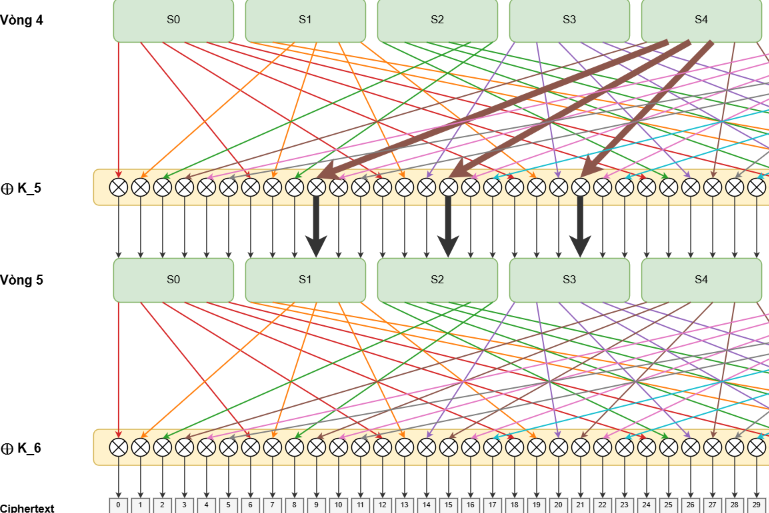

- Đây là round cuối, không mất tính tổng quát ta dời các round_key K_6 lên trước hoán vị và phép hoán vị thực hiện sau (sau này giải ra key chỉ cần hoán vị lại key là ra round_key cuối)
- Gọi $y$ là trạng thái sau sbox vòng 5, $x$ là trước sbox và $k$ là round_key cuối (đã dời) và $v$ là sau khi áp round_key.
- Gọi $s[]$ là phép biến đổi nhận $x$ và thu được $y$

Oke ta sẽ phân tích như sau:
- Với mỗi ciphertext ta nghịch đảo hoán vị ta được *v*, vì bài toán ta chỉ xét các sbox S1 -> S3 nên ta thu hẹp về các bit từ 6 đến 23
- Ở phương pháp linear attack với mỗi cặp plain, cipher thu kéo về được cặp $b = x_{24}^0 + x_{29}^0$ và $v$ với trọng số $T[v, b]$
- Với mỗi $y$ đặt hàm $fbox[y] = fbox[v \oplus k] = S1[y[0..6]][3] + S2[y[6..12]][3] + S3[y[12..18]][3]$. Và hiển nhiên $b = fbox[k \oplus v]$ (1) là xấp xỉ tuyến tính ta tìm được ở trước nếu k đúng là key.
- Bài toán ta giải là đến xem trong từng key thì key nào có bias phương trình 1 cao nhất là key.

Ở trên là phương pháp cũ, giờ thay vì ta đến phương trình có bias cao nhất $bias[k] = |count[k] - \frac{N}{2}|$, với mỗi phương trình thỏa ta cộng 1 và không thỏa là -1 vào mảng đếm mới là $R[k]$ và hiển nhiên $R[k] = count[k] - (N - count[k])$ và hiển nhiên là $|R[k]| = 2 \times bias[k]$ nên chỉ đếm R cao nhất là đủ.

*Làm thế nào tính R?*  
Dễ thấy rằng $R[k] = \sum_{v, b}((-1)^b \times (-1)^{fbox[v \oplus k]})$. Nếu $b = fbox[k \oplus v]$ thì hiển nhiên nó trả về 1 nếu khác thì -1.
$$
R[k] = \sum_{v, b}(T[v, b] \times (-1)^b \times (-1)^{fbox[v \oplus k]})
$$
$$
R[k] = \sum_{v}((-1)^{fbox[v \oplus k]} \times \sum_{b}(T[v, b] \times ((-1)^b)))
$$
Đặt $A[v \oplus k] = (-1)^{fbox[v \oplus k]}$ và $B[v] = \sum_{b}(T[v, b] \times ((-1)^b))$. Ta có
$$
R[k] = \sum_{v}(A[v]B[v \oplus k]) (*)
$$
Đây là 1 **Xor-convolution**. Ta có miền của 2 hàm $A, B$ là từ $1..2^{18}$ -> Dựng 2 vector $A[i]$ và $B[i]$ (mất $O(n)$) rồi tính $R[i]$ (mất $O(n^2)$). Do đó ta dùng **Walsh-Hadarmad transform** để biến đổi toàn bộ vector $A,B,R$ thành $\hat{A},\hat{B},\hat{R}$ chỉ mất $O(nlogn)$ và thoe tính chất của phép biến đổi ta thu được quan hệ mới là $\hat{A}[i]\hat{B}[i]=\hat{R}[i]$ do đó định giá $\hat{R}$ chỉ mất $O(n)$ và biến đổi lần nữa $R=\frac{1}{n}\hat{\hat{R}}$. Cuối cùng để tốn $O(nlogn)$
> Lưu ý: cách hiểu hàm hay vector ở đây là tương đương nhau, coi vector như hàm từ tập index và từng entry của nó


Chi tiết thuật toán Walsh-Hadarmad transform ta sẽ triển khai ở dưới

In [55]:
def fwht(a):
    a = list(a)
    n = len(a)
    assert n & (n - 1) == 0
    h = 1
    while h < n:
        for i in range(0, n, 2 * h):
            for j in range(i, i + h):
                x, y = a[j], a[j + h]
                a[j], a[j + h] = x + y, x - y
        h *= 2
    return a

def ifwht(a):
    n = len(a)
    return [v // n for v in fwht(a)]

def xor_convolution(a, b):
    return ifwht([x*y for x, y in zip(fwht(a), fwht(b))])

In [56]:
B = [0] * 2**18
RC = 1_000_000
y_index = [miniSPN.perm[i] for i in range(6, 24)]

pbar = tqdm.tqdm(total=N, unit='pair')
with open('minispn_cpt.bin', 'rb') as f:
    for base in range(0, N, RC):
        cpt = f.read(RC * 6)
        for i in range(RC):
            y = int.from_bytes(cpt[6*i:6*(i+1)], 'big')
            x = base + i
            v = 0
            for i in range(18):
                v |= ((y >> (47 - y_index[i])) & 1) << (17 - i)
            B[v] += (-1)**((x >> (47 - 24)) ^ (x >> (47 - 29)) & 1)
            pbar.update(1)

inv = [0] * 64
for a, b in enumerate(miniSPN.sbox):
    inv[b] = a
A = [0] * 2**18
for i in range(2**18):
    vi = [inv[i >> 12], inv[(i >> 6) & 63], inv[i & 63]]
    A[i] = (-1) ** (((vi[0] >> 2) ^ (vi[1] >> 2) ^ (vi[2] >> 2)) & 1)

R  = xor_convolution(A, B)
Rs = sorted(R, key=abs, reverse=True)
k1 = R.index(Rs[0])


  0%|          | 0/33000000 [00:00<?, ?pair/s]

100%|██████████| 33000000/33000000 [08:04<00:00, 68169.88pair/s] 


In [57]:
B = [0] * 2**18
RC = 1_000_000
y_index = [miniSPN.perm[i] for i in list(range(0, 6)) + list(range(12, 18)) + list(range(30, 36))]

pbar = tqdm.tqdm(total=N, unit='pair')
with open('minispn_cpt.bin', 'rb') as f:
    for base in range(0, N, RC):
        cpt = f.read(RC * 6)
        for i in range(RC):
            y = int.from_bytes(cpt[6*i:6*(i+1)], 'big')
            x = base + i
            v = 0
            for i in range(18):
                v |= ((y >> (47 - y_index[i])) & 1) << (17 - i)
            B[v] += (-1)**((x >> (47 - 24)) ^ (x >> (47 - 29)) & 1)
            pbar.update(1)

inv = [0] * 64
for a, b in enumerate(miniSPN.sbox):
    inv[b] = a
A = [0] * 2**18
for i in range(2**18):
    vi = [inv[i >> 12], inv[(i >> 6) & 63], inv[i & 63]]
    A[i] = (-1) ** (((vi[0] >> 2) ^ (vi[1] >> 2) ^ (vi[2] >> 2)) & 1)

R  = xor_convolution(A, B)

mid = (k1 >> 6) & 63
cands = [k for k in range(2**18) if (k >> 6) & 63 == mid]
cands.sort(key=lambda k: abs(R[k]), reverse=True)
k2 = cands[0]
print(R[cands[0]], R[cands[1]])

  0%|          | 0/33000000 [00:00<?, ?pair/s]

-27436 -22676


### **Tiếp tục brute toàn bộ phần còn lại của key**

In [60]:
def reverse_key(last_key: list[int]):
    state = last_key
    for i in range(miniSPN.num_rounds, -1, -1):
        round_constant = miniSPN._num2bit((i + 1) * 1337, miniSPN.block_size)
        state = miniSPN._rotate(miniSPN._xor(miniSPN._reverse_substitute(state), round_constant), 48 - 13)
    return state

assert reverse_key(miniSPN._expand_key([0]*48)[-1]) == [0]*48

In [73]:
with open('minispn_cpt.bin', 'rb') as f:
    check_cpt = f.read(6)

bit_cpt = byte2bit(check_cpt)

def find_key():
    for k2 in cands[4:8]:
        print(f'Candidate {k2}')
        k_known = (k1 << 24) | (k2 >> 12) << 42 | (k2 & 63) << 12
        for k_guess in tqdm.trange(2**18):
            k_test = k_known | (k_guess & 63) << 18 | k_guess >> 6
            miniSPN.add_key(reverse_key(miniSPN._permutate(int2bit(k_test, 48))))
            plt = miniSPN.decrypt_block(bit_cpt)
            if sum(plt) == 0:
                print(f'Found key = {k_test}')
                return k_test
key = find_key()


Candidate 172675


  0%|          | 0/262144 [00:00<?, ?it/s]

Found key = 189058766876787


In [81]:
master_key = reverse_key(miniSPN._permutate(int2bit(key, 48)))
hex_key    = '%012x' % int(''.join(map(str, master_key)), 2)

io = process(['python', 'oracle.py'], cwd='toys')
io.recvuntil(b'>>> ').decode()
io.sendline(b'1')
io.recvuntil(b'>>> ').decode()
io.sendline(b'c9ea7c445c8b75f9')

io.recvuntil(b'>>> ').decode()
io.sendline(b'3')
io.recvuntil(b'>>> ').decode()
io.sendline(hex_key.encode())
io.recvline()


[x] Starting local process '/home/hikinx/miniforge3/envs/sage/bin/python'
[+] Starting local process '/home/hikinx/miniforge3/envs/sage/bin/python': pid 79070


b'CONGRATULATION!!! -> FLAG: kitsu{this_just_is_a_test_flag_for_spn}\n'